In [ ]:
# import kagglehub

# # Download latest version
# path = kagglehub.dataset_download("shubhambathwal/flight-price-prediction")

# print("Path to dataset files:", path)

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [24]:
df = pd.read_csv("../../../../datasets/flight_fare_dataset_shubham_bathwal/Clean_dataset.csv")
df.head()

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [25]:
df.airline.value_counts()

airline
Vistara      127859
Air_India     80892
Indigo        43120
GO_FIRST      23173
AirAsia       16098
SpiceJet       9011
Name: count, dtype: int64

In [26]:
df.source_city.value_counts()

source_city
Delhi        61343
Mumbai       60896
Bangalore    52061
Kolkata      46347
Hyderabad    40806
Chennai      38700
Name: count, dtype: int64

In [27]:
df.destination_city.value_counts()

destination_city
Mumbai       59097
Delhi        57360
Bangalore    51068
Kolkata      49534
Hyderabad    42726
Chennai      40368
Name: count, dtype: int64

In [28]:
df.departure_time.value_counts()

departure_time
Morning          71146
Early_Morning    66790
Evening          65102
Night            48015
Afternoon        47794
Late_Night        1306
Name: count, dtype: int64

In [29]:
df.arrival_time.value_counts()

arrival_time
Night            91538
Evening          78323
Morning          62735
Afternoon        38139
Early_Morning    15417
Late_Night       14001
Name: count, dtype: int64

In [30]:
df.stops.value_counts()

stops
one            250863
zero            36004
two_or_more     13286
Name: count, dtype: int64

In [31]:
df['class'].value_counts()

class
Economy     206666
Business     93487
Name: count, dtype: int64

In [32]:
display(df.duration.min())
display(df.duration.max())
display(df.duration.median())

np.float64(0.83)

np.float64(49.83)

np.float64(11.25)

Preprocessing

In [33]:
df = df.drop('Unnamed: 0', axis=1)
df = df.drop("flight", axis=1)

df['class'] = df['class'].apply(lambda x : 1 if x == "Business" else 0)

In [34]:
df.stops = pd.factorize(df.stops)[0]
df.sample(10)

,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
95878,GO_FIRST,Bangalore,Morning,1,Night,Mumbai,0,9.33,13,5177
173117,Vistara,Hyderabad,Afternoon,1,Morning,Kolkata,0,20.17,23,5960
72244,Indigo,Mumbai,Evening,0,Night,Hyderabad,0,1.33,16,2901
26505,Indigo,Delhi,Afternoon,1,Night,Kolkata,0,6.33,37,6092
170284,Indigo,Hyderabad,Morning,1,Evening,Bangalore,0,7.25,46,2564
174701,Indigo,Hyderabad,Afternoon,1,Night,Kolkata,0,7.00,36,7167
236684,Air_India,Mumbai,Evening,1,Evening,Kolkata,1,24.83,33,45230
257665,Vistara,Bangalore,Evening,1,Afternoon,Hyderabad,1,16.33,29,37985
247980,Vistara,Bangalore,Morning,1,Evening,Delhi,1,10.25,41,50361
75355,Air_India,Mumbai,Early_Morning,1,Night,Hyderabad,0,16.58,36,4173


In [35]:
df = df.join(pd.get_dummies(df.airline, prefix='airline')).drop('airline', axis=1)
df = df.join(pd.get_dummies(df.source_city, prefix='source')).drop('source_city', axis=1)
df = df.join(pd.get_dummies(df.destination_city, prefix='destination')).drop('destination_city', axis=1)
df = df.join(pd.get_dummies(df.arrival_time, prefix='arrival')).drop('arrival_time', axis=1)
df = df.join(pd.get_dummies(df.departure_time, prefix='depart')).drop('departure_time', axis=1)

In [36]:
df

,stops,class,duration,days_left,price,airline_AirAsia,airline_Air_India,airline_GO_FIRST,airline_Indigo,airline_SpiceJet,...,arrival_Evening,arrival_Late_Night,arrival_Morning,arrival_Night,depart_Afternoon,depart_Early_Morning,depart_Evening,depart_Late_Night,depart_Morning,depart_Night
0,0,0,2.17,1,5953,False,False,False,False,True,...,False,False,False,True,False,False,True,False,False,False
1,0,0,2.33,1,5953,False,False,False,False,True,...,False,False,True,False,False,True,False,False,False,False
2,0,0,2.17,1,5956,True,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
3,0,0,2.25,1,5955,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,0,0,2.33,1,5955,False,False,False,False,False,...,False,False,True,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
300148,1,1,10.08,49,69265,False,False,False,False,False,...,True,False,False,False,False,False,False,False,True,False
300149,1,1,10.42,49,77105,False,False,False,False,False,...,False,False,False,True,True,False,False,False,False,False
300150,1,1,13.83,49,79099,False,False,False,False,False,...,False,False,False,True,False,True,False,False,False,False
300151,1,1,10.00,49,81585,False,False,False,False,False,...,True,False,False,False,False,True,False,False,False,False


Training Regression Model

In [37]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

X, y = df.drop('price', axis=1), df.price

In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size=0.2
)

In [39]:
reg = RandomForestRegressor()
reg.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [40]:
reg.score(X_test, y_test)

0.9860809105484241

In [41]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = reg.predict(X_test)
print("R2 : ", r2_score(y_test, y_pred))
print("MAE : ", mean_absolute_error(y_test, y_pred))
print("MSE : ", mean_squared_error(y_test, y_pred))
print("RMSE : ", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 :  0.9860809105484241
MAE :  1044.4708701234777
MSE :  7139913.046748976
RMSE :  2672.0615724097706


Text(0.5, 1.0, 'Prediction vs Actual Price')

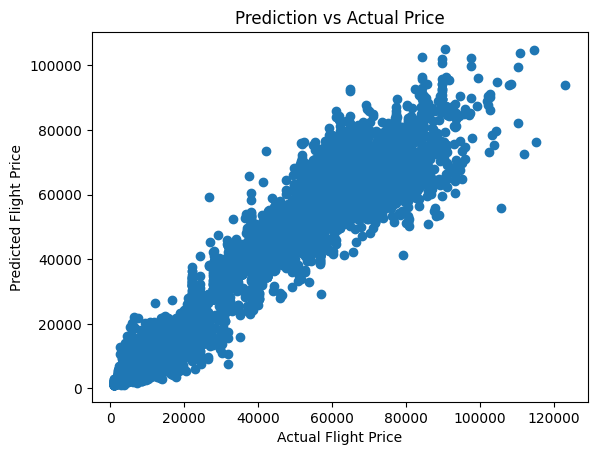

In [42]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred)
plt.xlabel("Actual Flight Price")
plt.ylabel("Predicted Flight Price")
plt.title("Prediction vs Actual Price")

In [43]:
df.price.describe()

count    300153.000000
mean      20889.660523
std       22697.767366
min        1105.000000
25%        4783.000000
50%        7425.000000
75%       42521.000000
max      123071.000000
Name: price, dtype: float64

In [44]:
importances = dict(zip(reg.feature_names_in_, reg.feature_importances_))
sorted_importances = sorted(importances.items(), key=lambda x: x[1], reverse=True)

sorted_importances

[('class', np.float64(0.8797470816728694)),
 ('duration', np.float64(0.05749515543397487)),
 ('days_left', np.float64(0.018728430070455854)),
 ('airline_Vistara', np.float64(0.005520981028698413)),
 ('airline_Air_India', np.float64(0.004487646299020416)),
 ('source_Delhi', np.float64(0.003919311085605496)),
 ('destination_Delhi', np.float64(0.0035357787909262414)),
 ('source_Mumbai', np.float64(0.0023019466396402297)),
 ('destination_Mumbai', np.float64(0.0019199416308113082)),
 ('stops', np.float64(0.0018519297080527124)),
 ('destination_Kolkata', np.float64(0.0017699842228122065)),
 ('source_Kolkata', np.float64(0.0016999403406748308)),
 ('destination_Hyderabad', np.float64(0.0015887163668253787)),
 ('arrival_Evening', np.float64(0.0014375143945758804)),
 ('source_Hyderabad', np.float64(0.0013733742220163171)),
 ('arrival_Night', np.float64(0.0011489379685874605)),
 ('depart_Evening', np.float64(0.0011450894973352055)),
 ('destination_Bangalore', np.float64(0.0010481772898446636)),
 

In [45]:
df.days_left.describe()

count    300153.000000
mean         26.004751
std          13.561004
min           1.000000
25%          15.000000
50%          26.000000
75%          38.000000
max          49.000000
Name: days_left, dtype: float64

<BarContainer object of 10 artists>

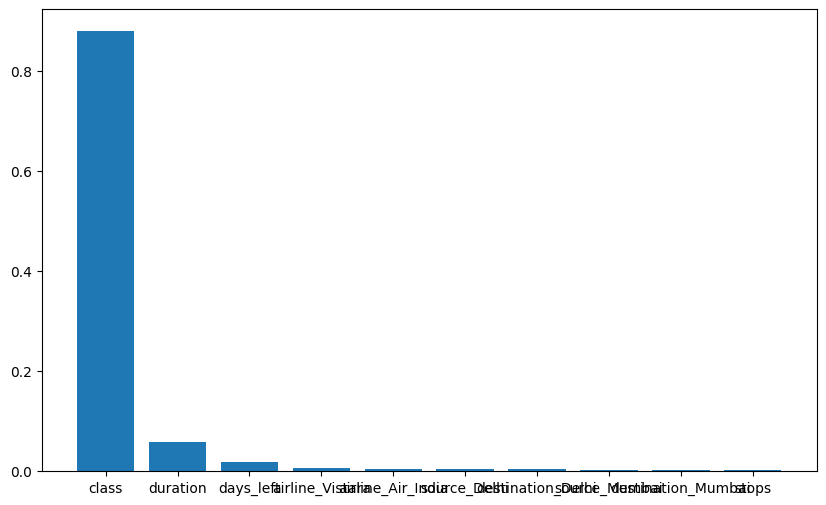

In [52]:
plt.figure(figsize=(10, 6))
plt.bar([x[0] for x in sorted_importances[:10]], [x[1] for x in sorted_importances[:10]])

In [ ]:
from sklearn.model_selection import GridSearchCV

reg_rf = RandomForestRegressor(n_jobs=-1)

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    'min_samples_split':[2, 5, 10],
    'min_samples_leaf': [1,2,4],
    'max_features': [None, 'sqrt']
}

grid_search = GridSearchCV(reg_rf, param_grid, cv=5)
grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_

In [53]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_dist = {
    "n_estimators": randint(100, 300),
    "max_depth": [None, 10, 20, 30, 40, 50],
    'min_samples_split':randint(2, 11),
    'min_samples_leaf': randint(1, 5),
    'max_features': [None, 'sqrt']
}

reg = RandomForestRegressor(n_jobs=-1)

random_search = RandomizedSearchCV(estimator=reg, param_distributions=param_dist, n_iter=2, cv=3,scoring='neg_mean_squared_error', verbose=2, random_state=42, n_jobs=-1)

random_search.fit(X_train, y_train)

best_regressor = random_search.best_estimator_

Fitting 3 folds for each of 2 candidates, totalling 6 fits


In [54]:
best_regressor.score(X_test, y_test)

0.9869123524153058

In [56]:

y_pred = best_regressor.predict(X_test)
print("R2 : ", r2_score(y_test, y_pred))
print("MAE : ", mean_absolute_error(y_test, y_pred))
print("MSE : ", mean_squared_error(y_test, y_pred))
print("RMSE : ", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 :  0.9869123524153058
MAE :  1102.4014721730914
MSE :  6713418.005272654
RMSE :  2591.0264385514583


Text(0.5, 1.0, 'Prediction vs Actual Price')

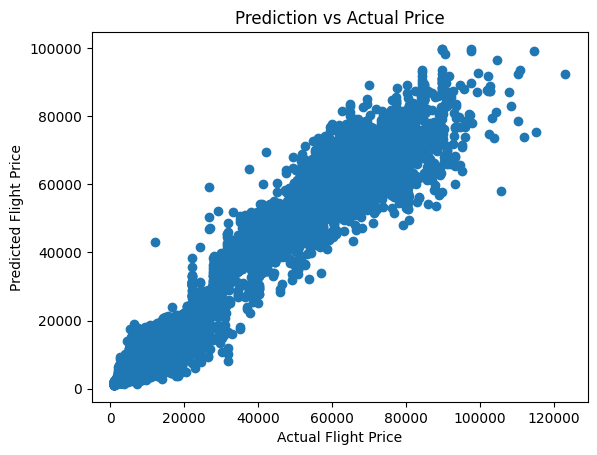

In [57]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Flight Price")
plt.ylabel("Predicted Flight Price")
plt.title("Prediction vs Actual Price")

In [72]:
best_regressor.predict(X_test.iloc[[56]])

array([4496.97050757])

In [73]:
y_test.iloc[[56]]

111005    4337
Name: price, dtype: int64